In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv(
    'winequality-red.csv',
    sep=';'
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1599, 1)


,"fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality"
0,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."
1,"7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.2,0...."
2,"7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0..."
3,"11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,..."
4,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."


In [ ]:
# step 1: Inspect the Dataset

In [ ]:
# Check column names
print(df.columns.tolist())

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'quality_label']


In [ ]:
# Dispaly the first five rows
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_label
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Low
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Low
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Low
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Medium
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Low


In [ ]:
# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
 12  quality_label         1599 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 162.5+ KB


In [ ]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1599
Number of columns: 13


In [ ]:
# descriptive statistics
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [ ]:
# Step 2: Check missing values and duplicate

In [ ]:
# Missing values
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [ ]:
# Duplicate rows
print(df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
quality_label           0
dtype: int64


In [ ]:
# Step 3: Check the distribution of wine quality

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 240


In [ ]:
# Check for invalid values
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1359, 13)


In [ ]:
print(df.columns.tolist())

['fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality']


In [ ]:
import pandas as pd

df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    sep=";"
)

print(df.columns.tolist())
print(df.head())

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.998

In [ ]:
df.columns = df.columns.str.strip()

print("Columns:", df.columns.tolist())

Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [ ]:
print("Quality scores:")
print(sorted(df["quality"].unique()))

print("\nMissing values remaining:")
print(df.isnull().sum().sum())

Quality scores:
[np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

Missing values remaining:
0


In [ ]:
print(df['quality'].value_counts().sort_index())

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


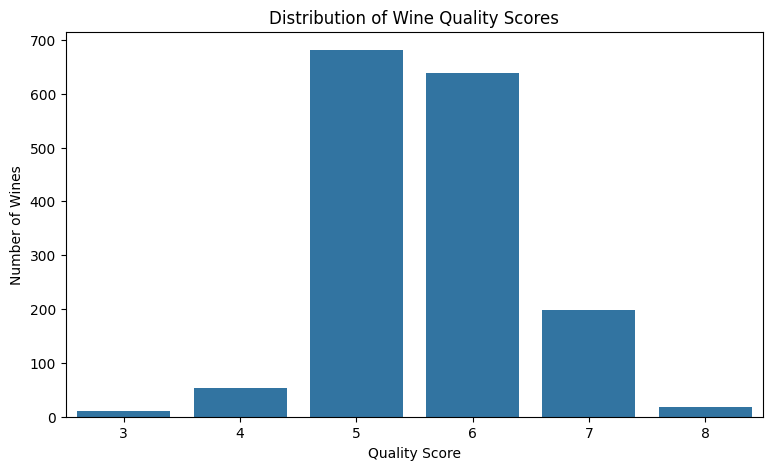

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='quality'
)

plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Number of Wines')

plt.show()

In [ ]:
# Step 4: Perform EDA on all chemical feacture

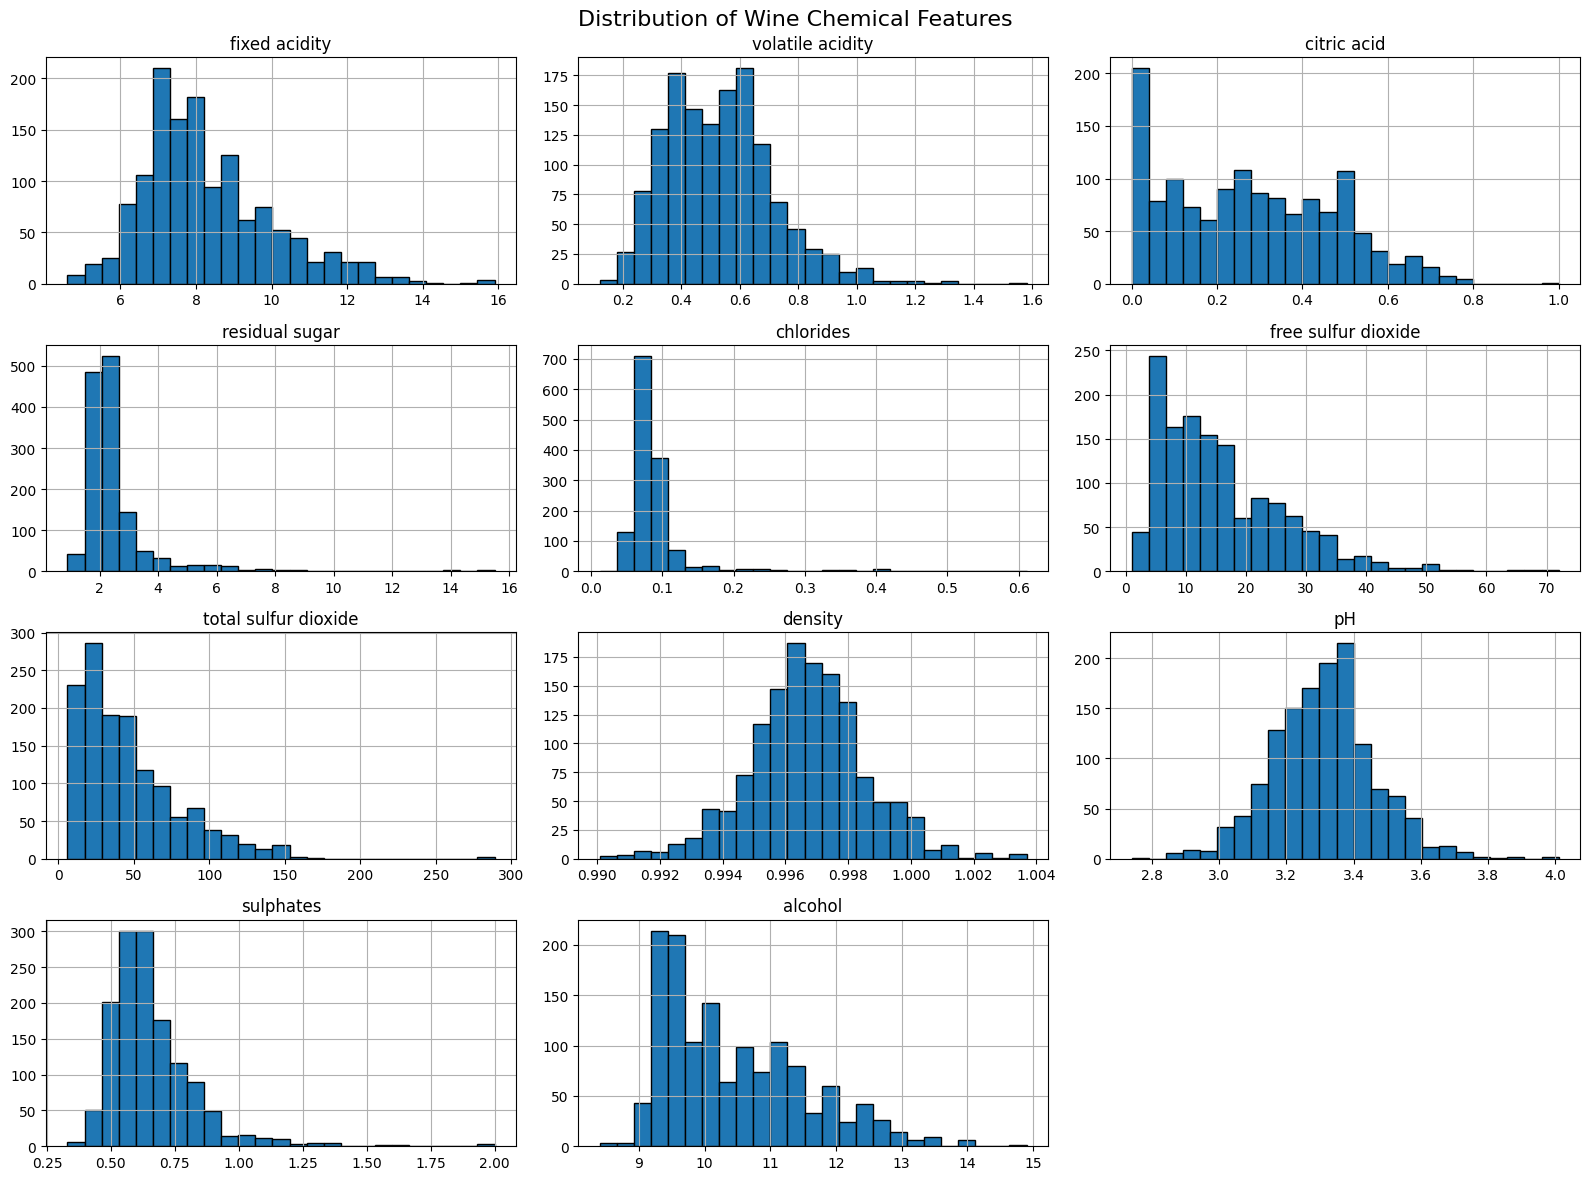

In [ ]:
# Plot the distribution of every feature
df.drop(columns=['quality']).hist(
    figsize=(16, 12),
    bins=25,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Wine Chemical Features',
    fontsize=16
)

plt.tight_layout()
plt.show()

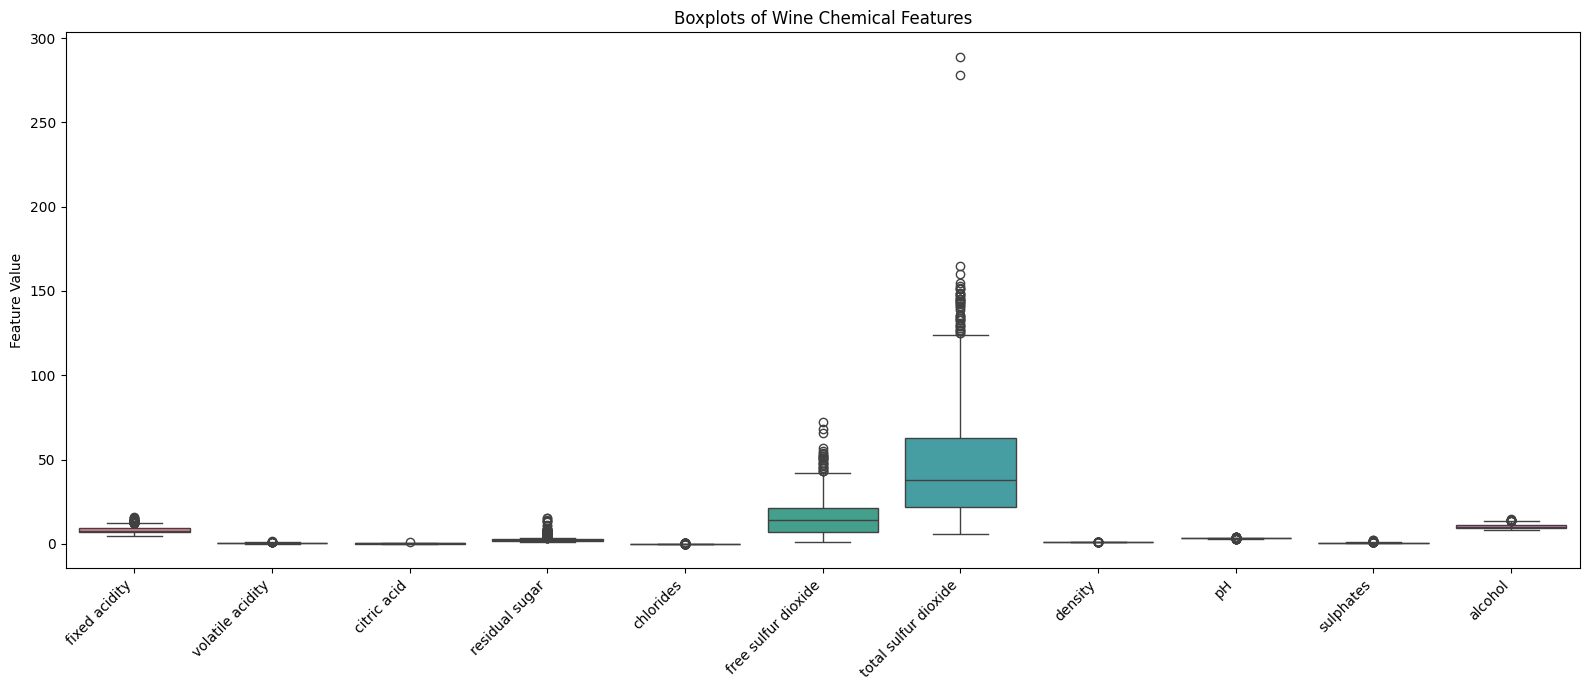

In [ ]:
# Box plot for chemical features
chemical_features = df.drop(
    columns=['quality']
).columns

plt.figure(figsize=(16, 7))

sns.boxplot(
    data=df[chemical_features]
)

plt.xticks(rotation=45, ha='right')
plt.title('Boxplots of Wine Chemical Features')
plt.ylabel('Feature Value')

plt.tight_layout()
plt.show()

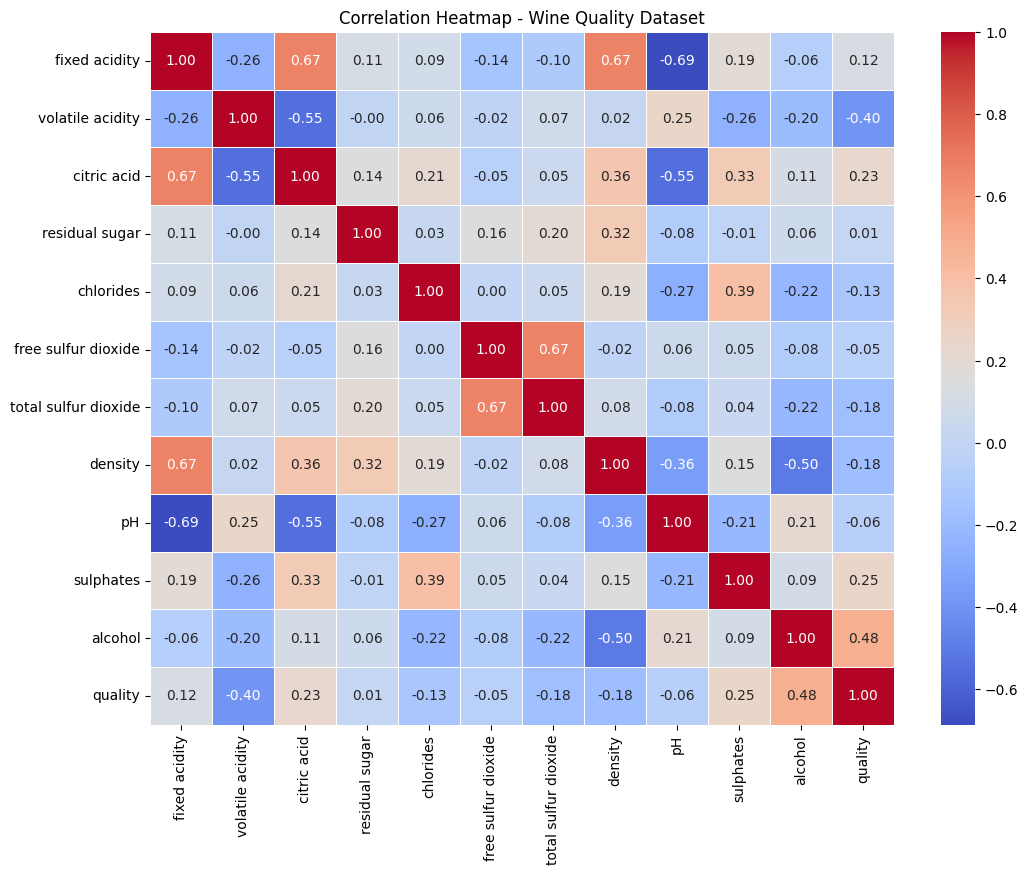

In [ ]:
# Correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap - Wine Quality Dataset')

plt.show()

In [ ]:
# find features correlated with quality
quality_corr = df.corr(numeric_only=True)['quality'].sort_values(
    ascending=False
)

print(quality_corr)

quality                 1.000000
alcohol                 0.480343
sulphates               0.248835
citric acid             0.228057
fixed acidity           0.119024
residual sugar          0.013640
free sulfur dioxide    -0.050463
pH                     -0.055245
chlorides              -0.130988
total sulfur dioxide   -0.177855
density                -0.184252
volatile acidity       -0.395214
Name: quality, dtype: float64


In [ ]:
# Syep 5: Feature eng. - create three quality classes

In [ ]:
# create the new target
def categorize_quality(score):
    if score <= 5:
        return 'Low'
    elif score == 6:
        return 'Medium'
    else:
        return 'High'

df['quality_label'] = df['quality'].apply(
    categorize_quality
)

df[['quality', 'quality_label']].head(10)

,quality,quality_label
0,5,Low
1,5,Low
2,5,Low
3,6,Medium
5,5,Low
6,5,Low
7,7,High
8,7,High
9,5,Low
10,5,Low


In [ ]:
# Check the new calss distribution
print(df['quality_label'].value_counts())

quality_label
Low       640
Medium    535
High      184
Name: count, dtype: int64


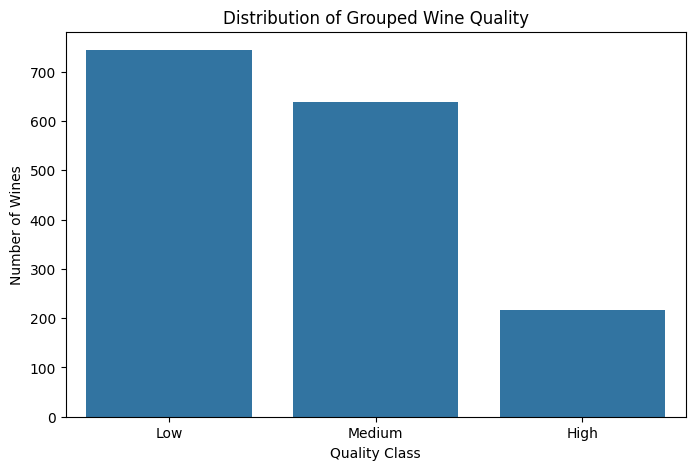

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='quality_label',
    order=['Low', 'Medium', 'High']
)

plt.title('Distribution of Grouped Wine Quality')
plt.xlabel('Quality Class')
plt.ylabel('Number of Wines')

plt.show()

In [ ]:
### Class Imbalance Discussion
'''
The wine quality dataset has an uneven distribution of target classes. Medium-quality wines may be more common than low- and high-quality wines. This imbalance can cause a classification model to favor the majority class and perform poorly on less frequent classes.

To address this issue, the dataset is divided using stratified sampling so that the class proportions are approximately preserved in the training and testing sets. Accuracy is evaluated alongside precision, recall, F1-score, and confusion matrices. Weighted F1-score summarizes performance while accounting for class frequencies, and macro F1-score gives equal weight to each class.

The class distribution should be checked before deciding whether additional techniques, such as class weighting, are necessary.
'''

'\nThe wine quality dataset has an uneven distribution of target classes. Medium-quality wines may be more common than low- and high-quality wines. This imbalance can cause a classification model to favor the majority class and perform poorly on less frequent classes.\n\nTo address this issue, the dataset is divided using stratified sampling so that the class proportions are approximately preserved in the training and testing sets. Accuracy is evaluated alongside precision, recall, F1-score, and confusion matrices. Weighted F1-score summarizes performance while accounting for class frequencies, and macro F1-score gives equal weight to each class.\n\nThe class distribution should be checked before deciding whether additional techniques, such as class weighting, are necessary.\n'

In [ ]:
# Step 6: Prepare input features and tareget

In [ ]:
X = df.drop(
    columns=['quality', 'quality_label']
)

y = df['quality_label']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Target classes:", y.unique())

Feature shape: (1599, 11)
Target shape: (1599,)
Target classes: ['Low' 'Medium' 'High']


In [ ]:
# step 7: Split the dataset into training and testing sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 1279
Testing samples: 320

Training class distribution:
quality_label
Low       0.465
Medium    0.399
High      0.136
Name: proportion, dtype: float64

Testing class distribution:
quality_label
Low       0.466
Medium    0.400
High      0.134
Name: proportion, dtype: float64


In [ ]:
# Step 8: Train Model 1 — Random Forest Classifier

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
# Step 9: Evaluate Random Forest

In [ ]:
# Accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy, 4))

Random Forest Accuracy: 0.7438


In [ ]:
# Classification report
print(
    classification_report(
        y_test,
        rf_pred,
        labels=['Low', 'Medium', 'High'],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.80      0.83      0.81       149
      Medium       0.69      0.71      0.70       128
        High       0.69      0.56      0.62        43

    accuracy                           0.74       320
   macro avg       0.73      0.70      0.71       320
weighted avg       0.74      0.74      0.74       320



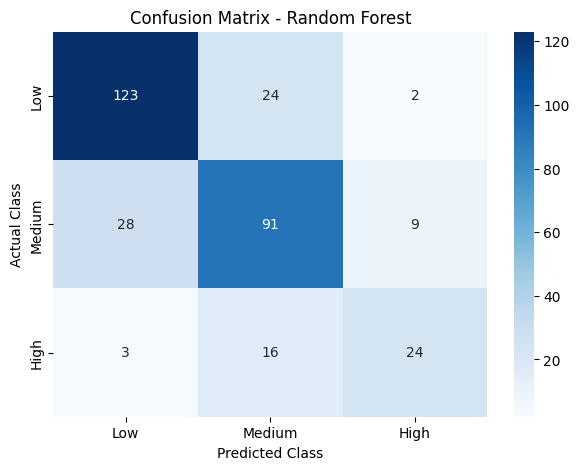

In [ ]:
# Confusion matrix
labels = ['Low', 'Medium', 'High']

rf_cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

In [ ]:
# Step 10: Train Model 2 — Support Vector Machine (SVM)

In [ ]:
sgd_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SGDClassifier(
        loss='hinge',
        max_iter=2000,
        tol=1e-3,
        random_state=42,
        class_weight='balanced'
    ))
])

sgd_model.fit(X_train, y_train)

sgd_pred = sgd_model.predict(X_test)

print("SGD Classifier trained successfully!")

SGD Classifier trained successfully!


In [ ]:
# Step 11: Evaluate SGD Classifier
# Accuracy
sgd_accuracy = accuracy_score(y_test, sgd_pred)

print("SGD Accuracy:", round(sgd_accuracy, 4))

SGD Accuracy: 0.5531


In [ ]:
# Classification report
print(
    classification_report(
        y_test,
        sgd_pred,
        labels=labels,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.70      0.74      0.72       149
      Medium       0.51      0.41      0.45       128
        High       0.23      0.33      0.27        43

    accuracy                           0.55       320
   macro avg       0.48      0.49      0.48       320
weighted avg       0.56      0.55      0.55       320



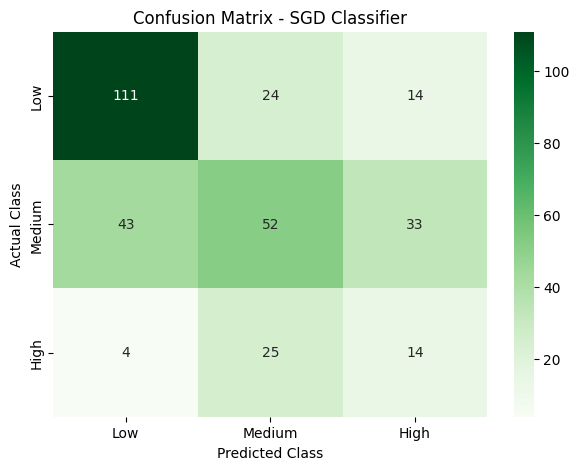

In [ ]:
# Confusion matrix
sgd_cm = confusion_matrix(
    y_test,
    sgd_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    sgd_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('Confusion Matrix - SGD Classifier')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

In [ ]:
# Step 12: Train Model 3 — Support Vector Classifier (SVC)

In [ ]:
svc_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        class_weight='balanced'
    ))
])

svc_model.fit(X_train, y_train)

svc_pred = svc_model.predict(X_test)

print("SVC trained successfully!")

SVC trained successfully!


In [ ]:
# Step 13: Evaluate SVC

In [ ]:
# Accuracy
svc_accuracy = accuracy_score(y_test, svc_pred)

print("SVC Accuracy:", round(svc_accuracy, 4))

SVC Accuracy: 0.6094


In [ ]:
# classification report
print(
    classification_report(
        y_test,
        svc_pred,
        labels=labels,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.73      0.77      0.75       149
      Medium       0.57      0.40      0.47       128
        High       0.41      0.70      0.51        43

    accuracy                           0.61       320
   macro avg       0.57      0.62      0.58       320
weighted avg       0.62      0.61      0.60       320



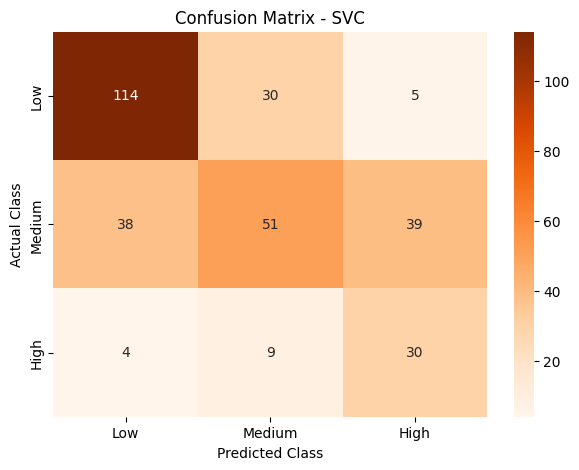

In [ ]:
# Confusion matrix
svc_cm = confusion_matrix(
    y_test,
    svc_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    svc_cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('Confusion Matrix - SVC')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

In [ ]:
# Step 14: Feature importance using Random Forest

In [ ]:
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                 Feature  Importance
10               alcohol    0.166807
9              sulphates    0.115793
1       volatile acidity    0.110162
6   total sulfur dioxide    0.094225
2            citric acid    0.089683
7                density    0.082704
4              chlorides    0.077093
0          fixed acidity    0.070227
8                     pH    0.067076
3         residual sugar    0.064586
5    free sulfur dioxide    0.061645


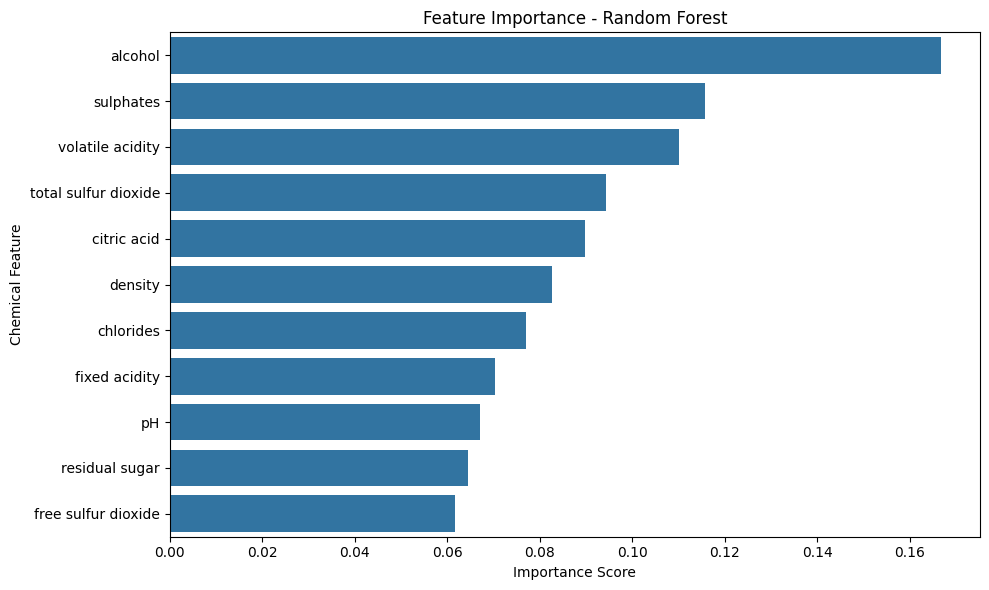

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Chemical Feature')

plt.tight_layout()
plt.show()

In [ ]:
#Interpretation
'''
The highest-ranked features contributed most to the Random Forest's impurity-based splits. Alcohol, sulphates, and volatile acidity may be useful predictors, but report the actual top features shown by your chart.
Feature importance does not establish causation, and impurity-based importance can be biased toward certain feature types.
'''

"\nThe highest-ranked features contributed most to the Random Forest's impurity-based splits. Alcohol, sulphates, and volatile acidity may be useful predictors, but report the actual top features shown by your chart.\nFeature importance does not establish causation, and impurity-based importance can be biased toward certain feature types.\n"

In [ ]:
# Step 15:Compare all three models

In [ ]:
model_predictions = {
    'Random Forest': rf_pred,
    'SGD Classifier': sgd_pred,
    'SVC': svc_pred
}

results = []

for model_name, predictions in model_predictions.items():

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Weighted Precision': precision_score(
            y_test, predictions,
            average='weighted',
            zero_division=0
        ),
        'Weighted Recall': recall_score(
            y_test, predictions,
            average='weighted',
            zero_division=0
        ),
        'Weighted F1': f1_score(
            y_test, predictions,
            average='weighted',
            zero_division=0
        ),
        'Macro F1': f1_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

         Model  Accuracy  Weighted Precision  Weighted Recall  Weighted F1  Macro F1
 Random Forest    0.7438              0.7419           0.7438       0.7418    0.7100
SGD Classifier    0.5531              0.5639           0.5531       0.5545    0.4822
           SVC    0.6094              0.6214           0.6094       0.6041    0.5761


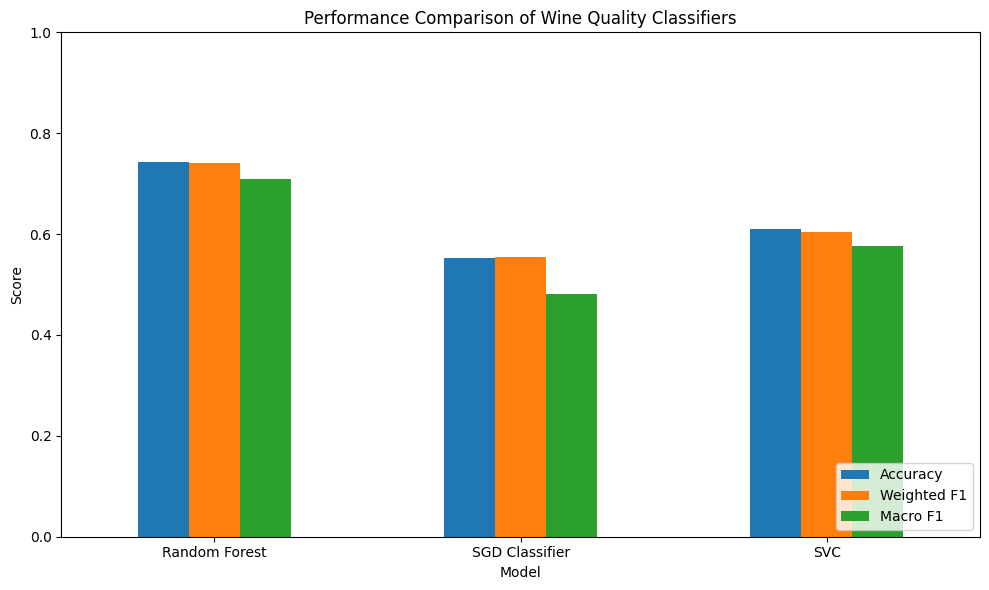

In [ ]:
results_plot = results_df.set_index('Model')[
    ['Accuracy', 'Weighted F1', 'Macro F1']
]

results_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Performance Comparison of Wine Quality Classifiers')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [ ]:
# Step 16: Identify the best-performing model

In [ ]:
best_row = results_df.loc[
    results_df['Macro F1'].idxmax()
]

print("Best model based on Macro F1:")
print(best_row.to_string())

Best model based on Macro F1:
Model                 Random Forest
Accuracy                    0.74375
Weighted Precision         0.741901
Weighted Recall             0.74375
Weighted F1                0.741806
Macro F1                    0.70999


In [ ]:
# Step 17: Save your model and results

In [ ]:
results_df.to_csv(
    '/content/wine_model_comparison.csv',
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [ ]:
#### Conclusion
'''
The Wine Quality Prediction project uses physicochemical properties to classify wine into low, medium, and high quality categories. Exploratory Data Analysis was performed to understand feature distributions, correlations, and class imbalance. Random Forest, SGD Classifier, and Support Vector Classifier were trained and evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices.

The models were compared using their test-set performance, with particular attention to macro F1-score because the quality classes may be imbalanced. The most suitable model should be selected based on its overall performance, ability to identify underrepresented classes, computational requirements, and suitability for the intended application.
'''

'\nThe Wine Quality Prediction project uses physicochemical properties to classify wine into low, medium, and high quality categories. Exploratory Data Analysis was performed to understand feature distributions, correlations, and class imbalance. Random Forest, SGD Classifier, and Support Vector Classifier were trained and evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices.\n\nThe models were compared using their test-set performance, with particular attention to macro F1-score because the quality classes may be imbalanced. The most suitable model should be selected based on its overall performance, ability to identify underrepresented classes, computational requirements, and suitability for the intended application.\n'